In [166]:
#Required Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [167]:
#Load Data
df = pd.read_csv("Unemployment in India.csv")

In [168]:
#Display overall Dataset
pd.set_option("display.max_columns",None)

In [169]:
df.head(10)

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural
5,Andhra Pradesh,31-10-2019,Monthly,3.52,12017412.0,43.01,Rural
6,Andhra Pradesh,30-11-2019,Monthly,4.12,11397681.0,41.00,Rural
7,Andhra Pradesh,31-12-2019,Monthly,4.38,12528395.0,45.14,Rural
8,Andhra Pradesh,31-01-2020,Monthly,4.84,12016676.0,43.46,Rural
9,Andhra Pradesh,29-02-2020,Monthly,5.91,11723617.0,42.83,Rural


In [170]:
df.shape




(768, 7)

In [171]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    object 
 1    Date                                     740 non-null    object 
 2    Frequency                                740 non-null    object 
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    object 
dtypes: float64(3), object(4)
memory usage: 42.1+ KB


In [172]:
df.isnull().sum()

,0
Region,28
Date,28
Frequency,28
Estimated Unemployment Rate (%),28
Estimated Employed,28
Estimated Labour Participation Rate (%),28
Area,28


In [173]:
df.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
763,True
764,True
765,True
766,True


In [174]:
df.drop_duplicates()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural
...,...,...,...,...,...,...,...
749,West Bengal,29-02-2020,Monthly,7.55,10871168.0,44.09,Urban
750,West Bengal,31-03-2020,Monthly,6.67,10806105.0,43.34,Urban
751,West Bengal,30-04-2020,Monthly,15.63,9299466.0,41.20,Urban
752,West Bengal,31-05-2020,Monthly,15.22,9240903.0,40.67,Urban


In [175]:
#Remove Extra Space from Columns Name and add back to alist
df.columns = df.columns.str.strip()
df.columns.tolist()

['Region',
 'Date',
 'Frequency',
 'Estimated Unemployment Rate (%)',
 'Estimated Employed',
 'Estimated Labour Participation Rate (%)',
 'Area']

In [176]:
#Convert Date into Reap time format
df["Date"] = pd.to_datetime(df["Date"].astype(str).str.strip(),
                               dayfirst=True,
                               errors="coerce")

In [177]:
#CONVERT NUMERIC COLUMNS
numeric_columns = [
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)"
]

for column in numeric_columns:

  df[column] = pd.to_numeric(df[column],
                             errors = "coerce")

In [178]:
df.dtypes

,0
Region,object
Date,datetime64[ns]
Frequency,object
Estimated Unemployment Rate (%),float64
Estimated Employed,float64
Estimated Labour Participation Rate (%),float64
Area,object


In [179]:
df.isnull().sum()

,0
Region,28
Date,28
Frequency,28
Estimated Unemployment Rate (%),28
Estimated Employed,28
Estimated Labour Participation Rate (%),28
Area,28


In [180]:
df.describe()

,Date,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740,740.000000,7.400000e+02,740.000000
mean,2019-12-12 18:36:58.378378496,11.787946,7.204460e+06,42.630122
min,2019-05-31 00:00:00,0.000000,4.942000e+04,13.330000
25%,2019-08-31 00:00:00,4.657500,1.190404e+06,38.062500
50%,2019-11-30 00:00:00,8.350000,4.744178e+06,41.160000
75%,2020-03-31 00:00:00,15.887500,1.127549e+07,45.505000
max,2020-06-30 00:00:00,76.740000,4.577751e+07,72.570000
std,NaN,10.721298,8.087988e+06,8.111094


In [181]:
df["Region"].nunique()

28

In [182]:
df["Region"].unique()

array(['Andhra Pradesh', 'Assam', 'Bihar', 'Chhattisgarh', 'Delhi', 'Goa',
       'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu & Kashmir',
       'Jharkhand', 'Karnataka', 'Kerala', 'Madhya Pradesh',
       'Maharashtra', 'Meghalaya', 'Odisha', 'Puducherry', 'Punjab',
       'Rajasthan', 'Sikkim', 'Tamil Nadu', 'Telangana', 'Tripura',
       'Uttar Pradesh', 'Uttarakhand', 'West Bengal', nan, 'Chandigarh'],
      dtype=object)

In [183]:
#REGION-WISE AVERAGE UNEMPLOYMENT

reg_avg = df.groupby("Region")["Estimated Unemployment Rate (%)"].mean().sort_values(ascending=False)

In [184]:
display(reg_avg.reset_index())

,Region,Estimated Unemployment Rate (%)
0,Tripura,28.350357
1,Haryana,26.283214
2,Jharkhand,20.585000
3,Bihar,18.918214
4,Himachal Pradesh,18.540357
5,Delhi,16.495357
6,Jammu & Kashmir,16.188571
7,Chandigarh,15.991667
8,Rajasthan,14.058214
9,Uttar Pradesh,12.551429


In [185]:
#ADD MONTH AND MONTH NAME COLUMNS
df["Months"] = df["Date"].dt.month
df["Months_name"] = df["Date"].dt.strftime("%B")

In [186]:
df.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area,Months,Months_name
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural,5.0,May
1,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural,6.0,June
2,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural,7.0,July
3,Andhra Pradesh,2019-08-31,Monthly,3.32,12285693.0,43.97,Rural,8.0,August
4,Andhra Pradesh,2019-09-30,Monthly,5.17,12256762.0,44.68,Rural,9.0,September


In [187]:
#MONTH-WISE AVERAGE UNEMPLOYMENT
monthly_avg = df.groupby("Date")["Estimated Unemployment Rate (%)"].mean().sort_values(ascending=False)
display(monthly_avg.reset_index())

,Date,Estimated Unemployment Rate (%)
0,2020-05-31,24.875294
1,2020-04-30,23.641569
2,2020-06-30,11.903600
3,2020-03-31,10.700577
4,2020-02-29,9.964717
5,2020-01-31,9.950755
6,2019-10-31,9.900909
7,2019-11-30,9.868364
8,2019-08-31,9.637925
9,2019-12-31,9.497358


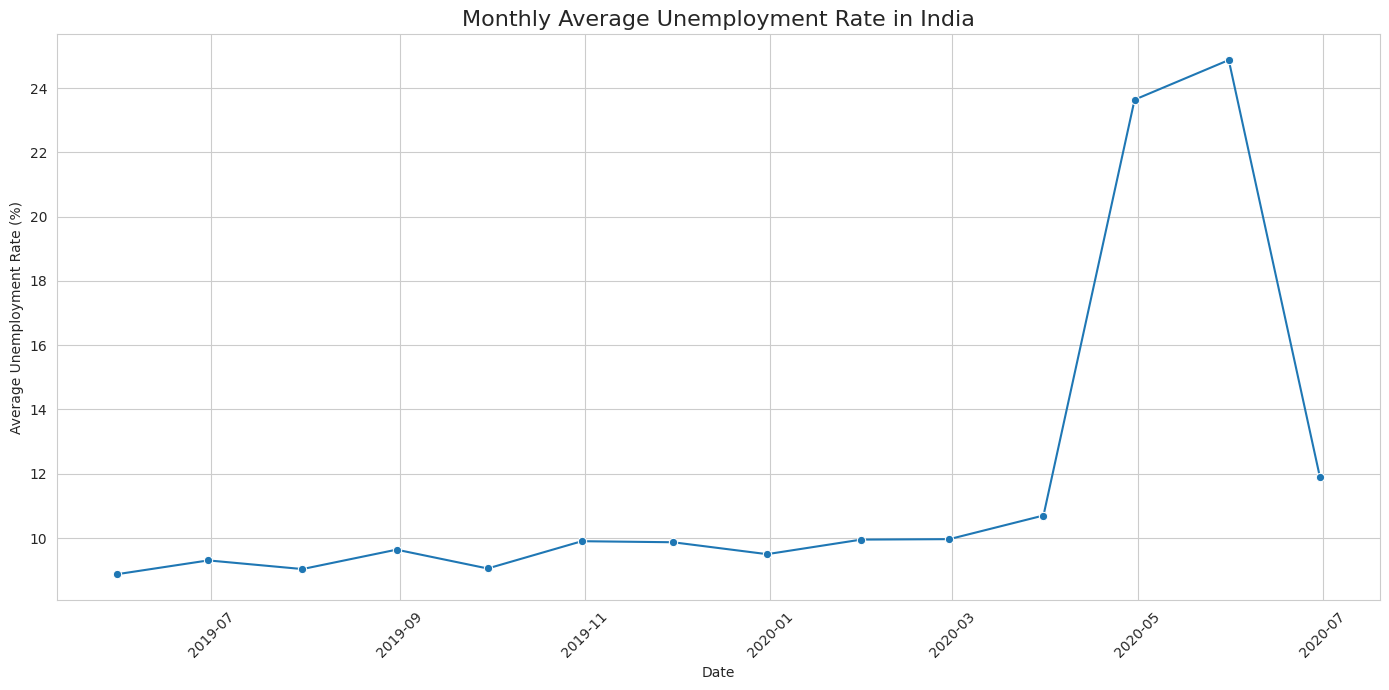

In [188]:
#MONTHLY TREND OF UNEMPLOYMENT
plt.figure(figsize=(14, 7))

sns.lineplot(
    data=monthly_avg.reset_index(),
    x="Date",
    y="Estimated Unemployment Rate (%)",
    marker="o"
)

plt.title(
    "Monthly Average Unemployment Rate in India",
    fontsize=16
)

plt.xlabel("Date")
plt.ylabel("Average Unemployment Rate (%)")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

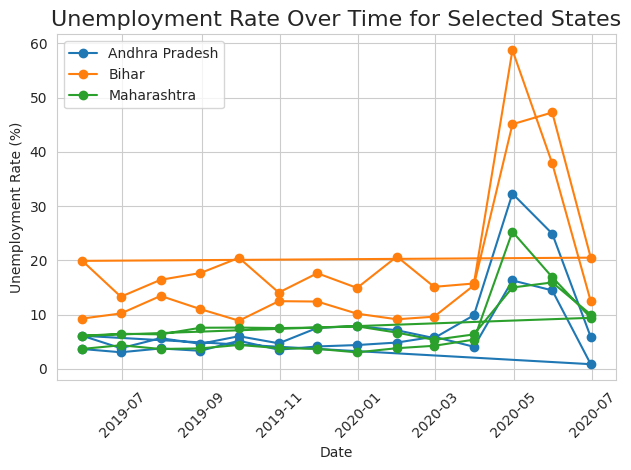

In [189]:
#TIME-SERIES ANALYSIS FOR 3 MAJOR STATES
# First check the exact region names using:
# print(df["Region"].unique())
selected_state = [
    "Andhra Pradesh",
    "Bihar",
    "Maharashtra"
]

for state in selected_state:
  state_data = df[df["Region"] == state]
  plt.plot(state_data["Date"],state_data["Estimated Unemployment Rate (%)"],marker="o",label=state)

plt.title(
    "Unemployment Rate Over Time for Selected States",
    fontsize=16
)

plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")

plt.legend()

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()



In [190]:
#TOP 10 STATES WITH HIGHEST AVERAGE UNEMPLOYMENT
top10 = df.groupby("Region")["Estimated Unemployment Rate (%)"].mean().sort_values(ascending=False).head(10)
display(top10)


,Estimated Unemployment Rate (%)
Region,
Tripura,28.350357
Haryana,26.283214
Jharkhand,20.585000
Bihar,18.918214
Himachal Pradesh,18.540357
Delhi,16.495357
Jammu & Kashmir,16.188571
Chandigarh,15.991667
Rajasthan,14.058214


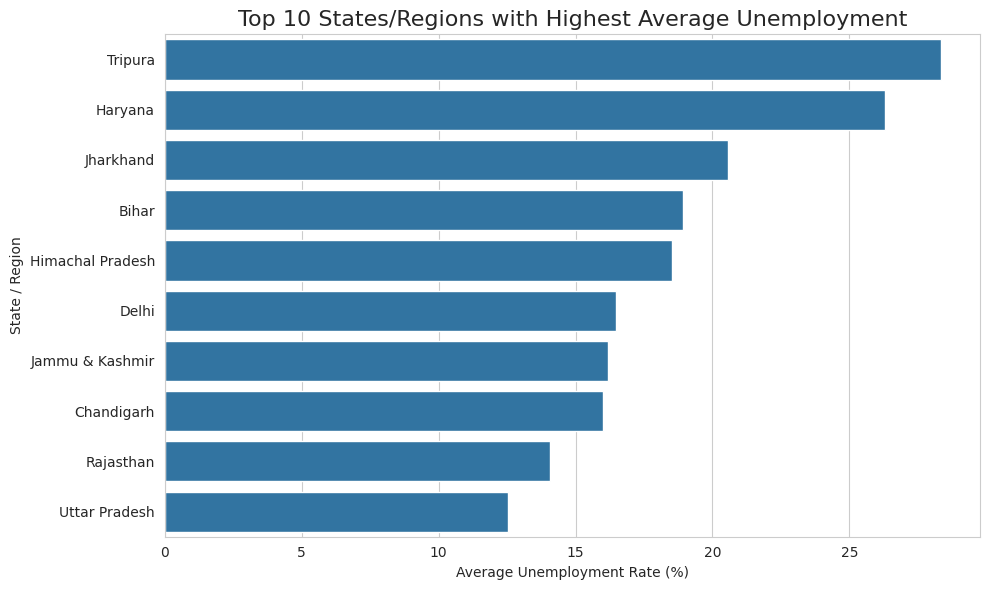

In [191]:
#BAR CHART - TOP 10 STATES
plt.figure(figsize=(10,6))
sns.barplot(x=top10.values, y=top10.index)
plt.title(
    "Top 10 States/Regions with Highest Average Unemployment",
    fontsize=16
)

plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("State / Region")

plt.tight_layout()
plt.show()

In [192]:
#CORRELATION ANALYSIS
correlation_data = df[
    [
        "Estimated Unemployment Rate (%)",
        "Estimated Employed",
        "Estimated Labour Participation Rate (%)"
    ]
]

correlation_matrix = correlation_data.corr()

print("Correlation Matrix:")
display(correlation_matrix)


Correlation Matrix:


,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
Estimated Unemployment Rate (%),1.000000,-0.222876,0.002558
Estimated Employed,-0.222876,1.000000,0.011300
Estimated Labour Participation Rate (%),0.002558,0.011300,1.000000


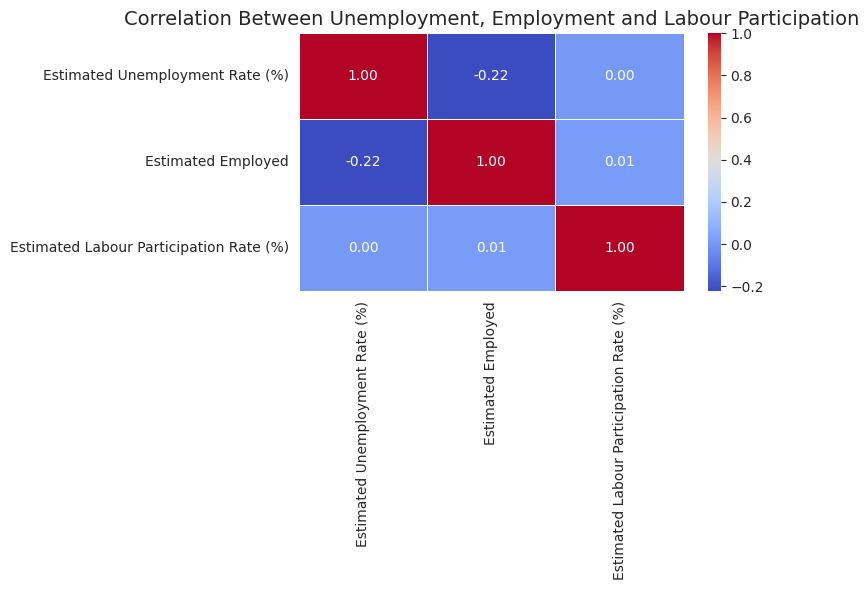

In [193]:
#CORRELATION HEATMAP
plt.figure(figsize=(8,6))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm",fmt=".2f",linewidths=0.5)
plt.title(
    "Correlation Between Unemployment, Employment and Labour Participation",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [194]:
#CREATE PRE-COVID AND POST-COVID PERIODS
#We use March 1, 2020 as the comparison cutoff
covid_data = pd.Timestamp("2020-03-01")
df["Period"] = np.where(df["Date"]<covid_data,"pre_covid","post_covid")
df["Period"].value_counts()

,count
Period,
pre_covid,536
post_covid,232


In [195]:
#PRE-COVID VS POST-COVID SUMMARY
period_summary = (
    df.groupby("Period")[
        [
            "Estimated Unemployment Rate (%)",
            "Estimated Employed",
            "Estimated Labour Participation Rate (%)"
        ]
    ]
    .mean()
)
display(period_summary)

,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
Period,,,
post_covid,17.774363,6.517203e+06,39.330049
pre_covid,9.509534,7.466028e+06,43.886119


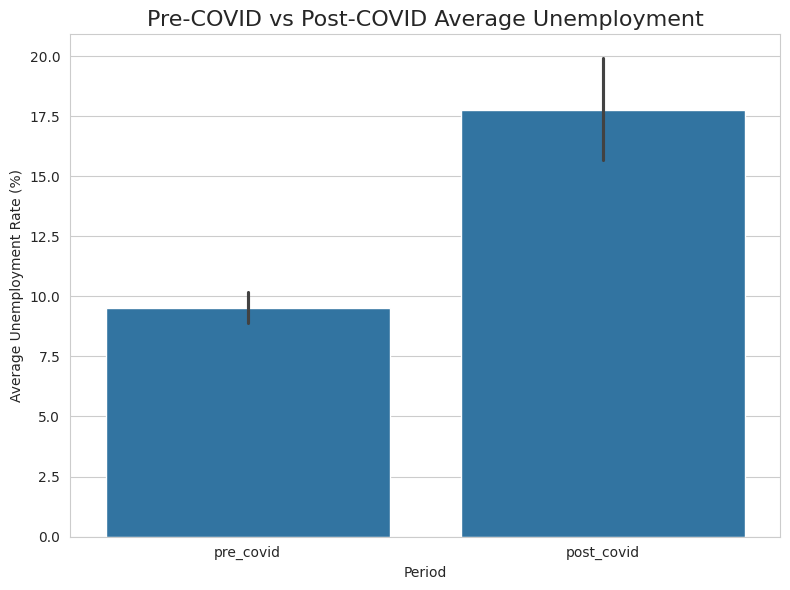

In [196]:
#PRE-COVID VS POST-COVID UNEMPLOYMENT BAR CHART
plt.figure(figsize=(8, 6))

sns.barplot(
    data=df,
    x="Period",
    y="Estimated Unemployment Rate (%)"
)

plt.title(
    "Pre-COVID vs Post-COVID Average Unemployment",
    fontsize=16
)

plt.xlabel("Period")
plt.ylabel("Average Unemployment Rate (%)")

plt.tight_layout()
plt.show()


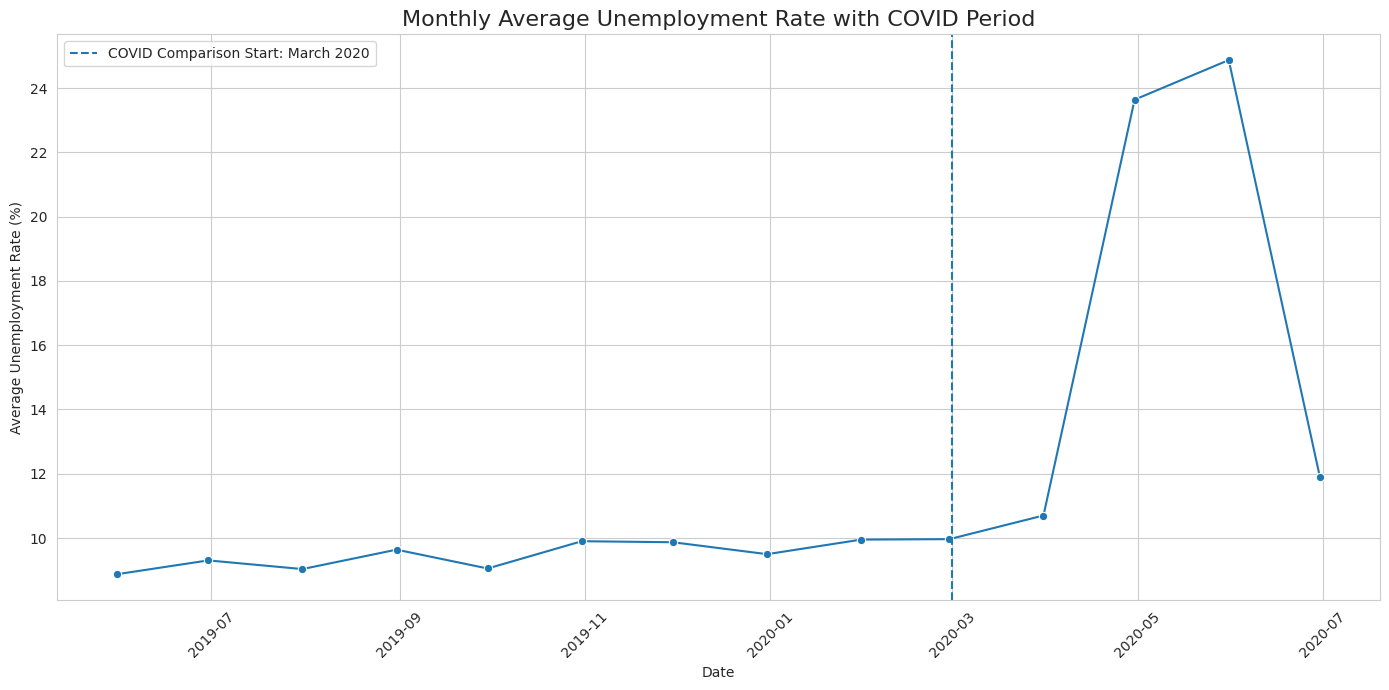

In [197]:
#MONTHLY TREND WITH COVID CUTOFF LINE
plt.figure(figsize=(14, 7))

sns.lineplot(
    data=monthly_avg.reset_index(),
    x="Date",
    y="Estimated Unemployment Rate (%)",
    marker="o"
)

plt.axvline(
    covid_data,
    linestyle="--",
    label="COVID Comparison Start: March 2020"
)

plt.title(
    "Monthly Average Unemployment Rate with COVID Period",
    fontsize=16
)

plt.xlabel("Date")
plt.ylabel("Average Unemployment Rate (%)")

plt.legend()

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


In [198]:
#OVERALL AVERAGE UNEMPLOYMENT
overall_average = df[
    "Estimated Unemployment Rate (%)"
].mean()

print(
    "Overall Average Unemployment Rate:",
    round(overall_average, 2),
    "%"
)


Overall Average Unemployment Rate: 11.79 %


In [199]:
#PRE-COVID AVERAGE UNEMPLOYMENT
pre_covid_average = df.loc[df["Period"] == "pre_covid", "Estimated Unemployment Rate (%)"].mean()

print(
    "Pre-COVID Average Unemployment Rate:",
    round(pre_covid_average, 2),
    "%"
)

Pre-COVID Average Unemployment Rate: 9.51 %


In [200]:
#POST-COVID AVERAGE UNEMPLOYMENT
post_covid_average = df.loc[df["Period"] == "post_covid", "Estimated Unemployment Rate (%)"].mean()

print(
    "Post-COVID Average Unemployment Rate:",
    round(post_covid_average, 2),
    "%"
)

Post-COVID Average Unemployment Rate: 17.77 %


In [201]:
# 34. DIFFERENCE BETWEEN PRE-COVID AND POST-COVID
# ------------------------------------------------------------

difference = post_covid_average - pre_covid_average

print(
    "Difference between Post-COVID and Pre-COVID:",
    round(difference, 2),
    "percentage points"
)

Difference between Post-COVID and Pre-COVID: 8.26 percentage points


In [202]:
#FINAL SUMMARY TABLE
summary = {
    "Total Rows": len(df),

    "Total Regions": df["Region"].nunique(),

    "Start Date": df["Date"].min(),

    "End Date": df["Date"].max(),

    "Overall Average Unemployment (%)":
        overall_average,

    "Pre-COVID Average Unemployment (%)":
        pre_covid_average,

    "Post-COVID Average Unemployment (%)":
        post_covid_average,

    "Post-COVID - Pre-COVID Difference":
        difference
}

summary_df = pd.DataFrame(
    summary.items(),
    columns=["Metric", "Value"]
)

print("FINAL PROJECT SUMMARY:")
display(summary_df)


FINAL PROJECT SUMMARY:


,Metric,Value
0,Total Rows,768
1,Total Regions,28
2,Start Date,2019-05-31 00:00:00
3,End Date,2020-06-30 00:00:00
4,Overall Average Unemployment (%),11.787946
5,Pre-COVID Average Unemployment (%),9.509534
6,Post-COVID Average Unemployment (%),17.774363
7,Post-COVID - Pre-COVID Difference,8.264829


In [203]:
#FINAL DATASET PREVIEW
print("Final Dataset:")
display(df.head())


Final Dataset:


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area,Months,Months_name,Period
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural,5.0,May,pre_covid
1,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural,6.0,June,pre_covid
2,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural,7.0,July,pre_covid
3,Andhra Pradesh,2019-08-31,Monthly,3.32,12285693.0,43.97,Rural,8.0,August,pre_covid
4,Andhra Pradesh,2019-09-30,Monthly,5.17,12256762.0,44.68,Rural,9.0,September,pre_covid
